# Causal measurement lab

Walkthrough notebook. It runs three studies on public data and shows the results:

1. **A randomized e-mail campaign test** (Hillstrom, 64,000 customers): readout, CUPED, GLM, Bayesian A/B, subgroups, proxy-metric validation, power planning
2. **Observational methods against known answers** (Hillstrom with targeting bias; LaLonde job training): propensity matching and weighting, doubly robust estimation, double ML
3. **Cluster randomization** (Tennessee STAR): cluster-robust inference, ICC, design effect, power by design

**In Google Colab:** Runtime → Run all. About 3 minutes; no accounts or keys needed.

In [1]:
import os
if not os.path.exists("run_all.py"):          # in Colab: fetch the project
    !git clone -q https://github.com/Dorcas-Okaidjah/causal-measurement-lab.git
    %cd causal-measurement-lab
!pip install -q -r requirements.txt

## 1. Check the methods on simulated data with known answers (~1 minute)

In [2]:
!python -m pytest -q 2>&1 | tail -2

...................                                                      [100%]
19 passed in 46.35s


## 2. Download and inspect the data

In [3]:
!python -m src.data --download
!python -m src.data --inspect

  could not reach www.minethatdata.com (<urlopen error [Errno -2] Name or service not known>); trying next source


  Hillstrom: saved from raw.githubusercontent.com (checksum verified)


  STAR: saved 11,598 students


  LaLonde: saved 445 NSW and 15,992 CPS records



Hillstrom: 64,000 customers
                visit  conversion   spend
arm                                      
Mens E-Mail    0.1828      0.0125  1.4226
No E-Mail      0.1062      0.0057  0.6528
Womens E-Mail  0.1514      0.0088  1.0772

LaLonde: 16,437 people


                       size     mean
sample         treat                
CPS comparison 0.0    15992  14847.0
NSW experiment 0.0      260   4555.0
               1.0      185   6349.0

STAR kindergarten: 5,786 students in 79 schools
              size   mean
class_type               
regular       2005 -0.000
regular+aide  2043  0.007
small         1738  0.179


## 3. Run all three studies

In [4]:
!python run_all.py

1/5 loading data


2/5 study 1: e-mail experiment readout


3/5 study 2: observational methods vs known answers


4/5 study 3: cluster randomization (STAR)


5/5 writing charts, tables and the summary


done in 24.8s -> /home/claude/causal-measurement-lab/reports/summary.md


## 4. The readout

In [5]:
from IPython.display import Markdown, Image, display
display(Markdown(open("reports/summary.md").read()))

# Measurement readout

## 1. E-mail campaign test (Hillstrom, randomized, 64,000 customers)

**Test health.** Group sizes Womens E-Mail: 21,387, Mens E-Mail: 21,307, No E-Mail: 21,306; sample-ratio check p = 0.90 (pass). Largest pre-period imbalance |SMD| = 0.012 (threshold 0.1).

| E-mail | Metric | Control | Treated | Effect (95% CI) | Lift (95% CI) | Holm p |
|---|---|---|---|---|---|---|
| Mens E-Mail | visit | 10.62% | 18.28% | 7.66% (7.00% to 8.32%) | +72% (+64% to +81%) | < 0.001 |
| Mens E-Mail | conversion | 0.57% | 1.25% | 0.68% (0.50% to 0.86%) | +119% (+77% to +171%) | < 0.001 |
| Mens E-Mail | spend | 0.65 | 1.42 | 0.77 (0.49 to 1.05) | +118% (+63% to +192%) | < 0.001 |
| Womens E-Mail | visit | 10.62% | 15.14% | 4.52% (3.89% to 5.16%) | +43% (+36% to +50%) | < 0.001 |
| Womens E-Mail | conversion | 0.57% | 0.88% | 0.31% (0.15% to 0.47%) | +54% (+23% to +94%) | < 0.001 |
| Womens E-Mail | spend | 0.65 | 1.08 | 0.42 (0.17 to 0.68) | +65% (+22% to +124%) | 0.001 |

Logistic GLM (visit, with pre-period covariates): odds ratio Mens E-Mail 1.91 (1.81-2.02), +7.6% points; Womens E-Mail 1.52 (1.44-1.61), +4.5% points.

**CUPED.** Using prior-year spend removed only 0.04% of the variance in spend, because it correlates just 0.02 with two-week spend. Variance reduction equals the squared correlation, so CUPED pays off only with a strongly predictive pre-period metric.

**Bayesian view.** Probability each e-mail increases spend: Mens E-Mail > 99.99% (expected loss if wrong $0.0000 per customer); Womens E-Mail 99.85% (expected loss if wrong $0.0001 per customer).

**Is visit a valid proxy for spend?** Visitors spend more (customer-level correlation 0.17), but across 18 segments the visit effect predicts the spend effect only weakly (split-sample correlation 0.27; 90% of splits between -0.08 and 0.50). At campaign level both e-mails earn about $10 and $9 per extra visit. Use visit as an early read on a whole campaign, not to choose segments.

**Next test.** With 21,306 customers per group the smallest detectable spend effect is $0.31 (48% of the control mean). Detecting a 10% spend lift needs 494,680 per group; a 10% visit lift needs 13,217.

## 2. Observational methods vs known answers

**Hillstrom with targeting bias (effect on visit rate, ATC).** Experimental truth 4.52% (3.89% to 5.16%).

| Method | Estimate | 95% CI | Gap to truth |
|---|---|---|---|
| Naive difference | 6.31% | 5.50% to 7.12% | +1.79 pts |
| Regression adjustment | 4.50% | 3.67% to 5.33% | -0.02 pts |
| Propensity matching | 4.32% | 3.69% to 4.95% | -0.20 pts |
| Inverse probability weighting | 4.59% | 3.73% to 5.44% | +0.07 pts |
| Doubly robust (AIPW) | 4.39% | 3.54% to 5.23% | -0.14 pts |
| Double ML | 4.57% | 3.74% to 5.40% | +0.05 pts |
| Doubly robust (AIPW), past spend unobserved | 4.74% | 3.92% to 5.55% | +0.21 pts |
| Inverse probability weighting, past spend unobserved | 4.89% | 4.08% to 5.71% | +0.37 pts |

Balance: largest |SMD| 0.48 before weighting, 0.06 after. Comparison-group share inside the treated propensity range: 100%.

**LaLonde: NSW trainees vs CPS comparison group (effect on 1978 earnings, ATT).** Experimental truth $1,794 ($479 to $3,109).

| Method | Estimate | 95% CI | Gap to truth |
|---|---|---|---|
| Naive difference | $-8,498 | $-9,641 to $-7,354 | -$10,292 |
| Regression adjustment | $1,567 | $330 to $2,804 | -$227 |
| Propensity matching | $1,723 | $279 to $3,168 | -$71 |
| Inverse probability weighting | $1,350 | $20 to $2,681 | -$444 |
| Doubly robust (AIPW) | $1,584 | $205 to $2,963 | -$210 |
| Double ML | $1,061 | $-205 to $2,327 | -$733 |

Balance: largest |SMD| 2.43 before weighting, 0.07 after. Comparison-group share inside the treated propensity range: 32%.

## 3. Cluster randomization (Tennessee STAR, kindergarten)

3,743 students in 79 schools, small vs regular classes, randomized within schools. School-level ICC 0.21, average 47 students per school. If whole schools were randomized instead, the design effect would be 10.9: these students would carry the information of about 344 independent students.

| Analysis | Effect (sd) | SE | 95% CI |
|---|---|---|---|
| Naive (students independent) | 0.179 | 0.031 | 0.118 to 0.240 |
| Cluster-robust by school | 0.179 | 0.054 | 0.073 to 0.285 |
| School fixed effects + cluster-robust | 0.206 | 0.056 | 0.097 to 0.315 |
| + student covariates | 0.206 | 0.053 | 0.102 to 0.311 |

Power to detect 0.15 sd: randomizing students 97%; randomizing schools 23%. Randomizing schools but analysing students as independent declared a significant effect 52% of the time when there was none (should be 5%).



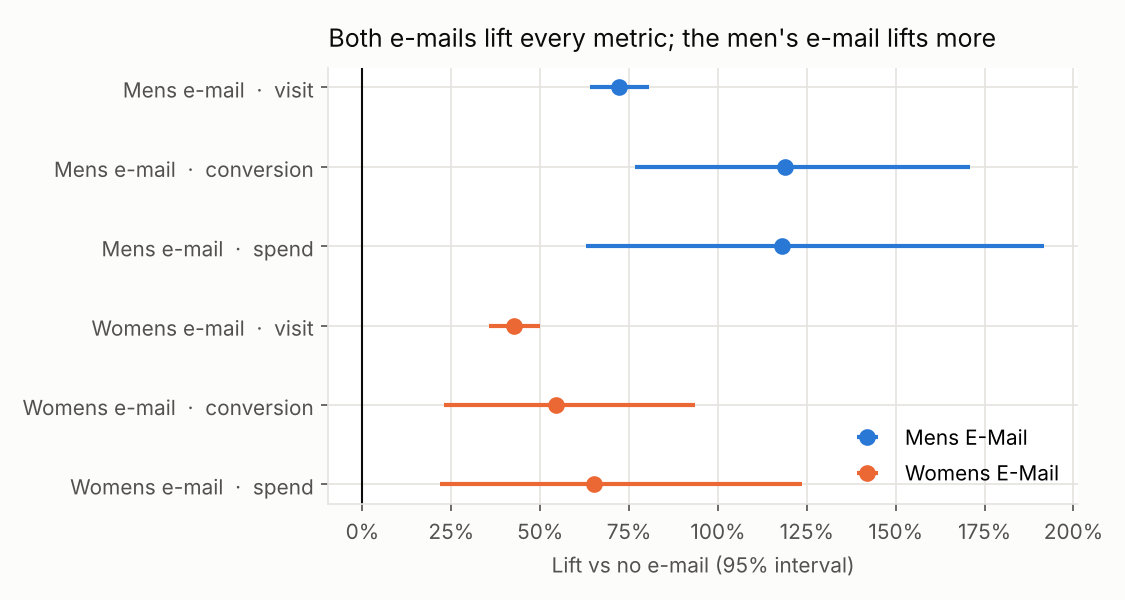

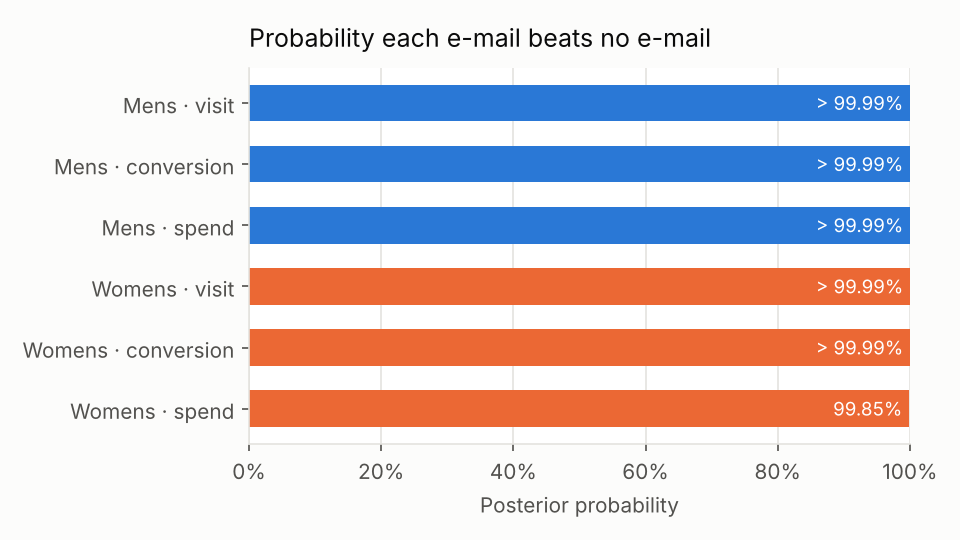

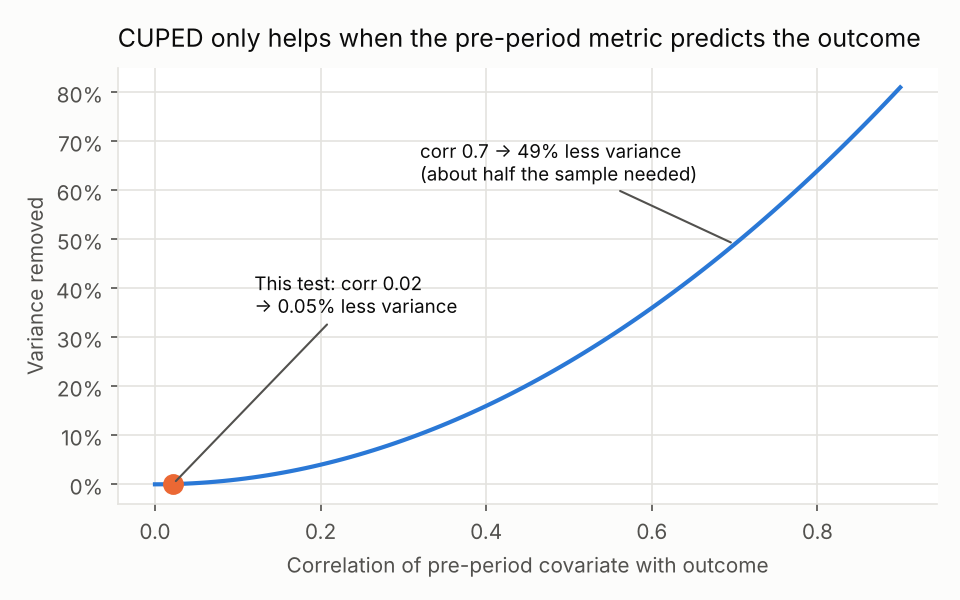

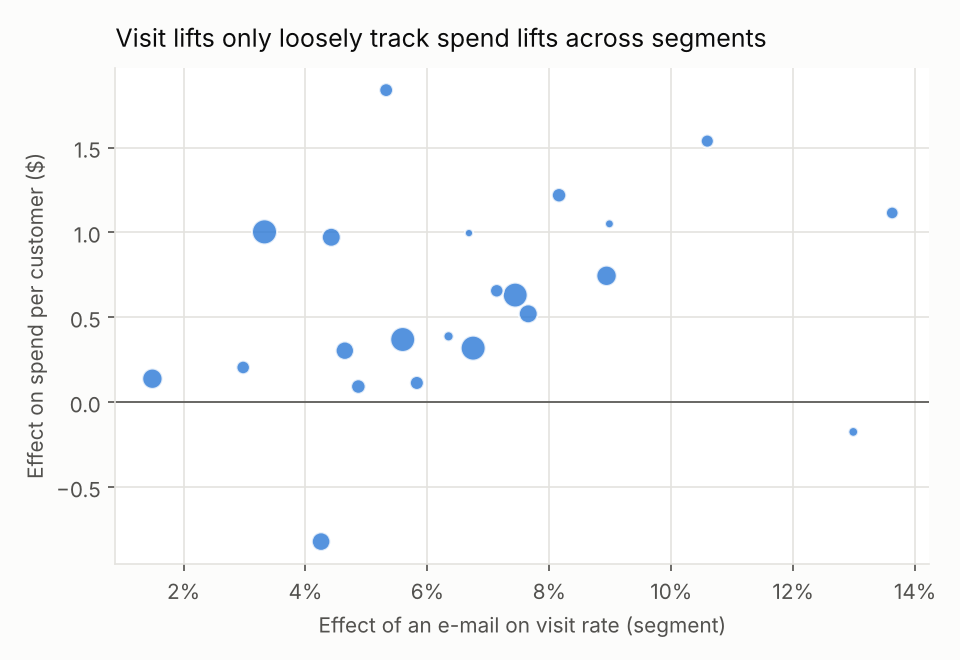

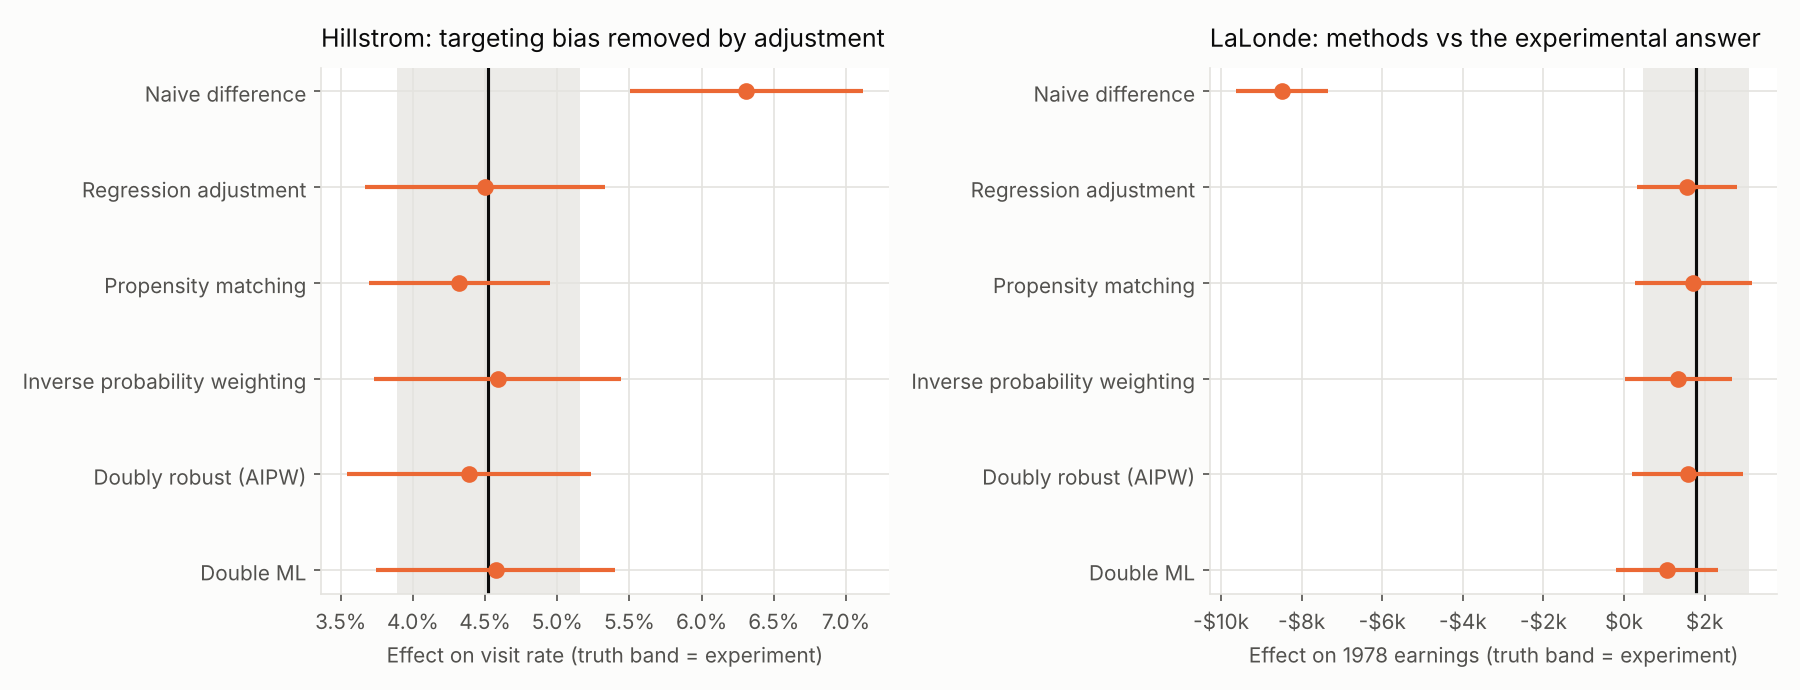

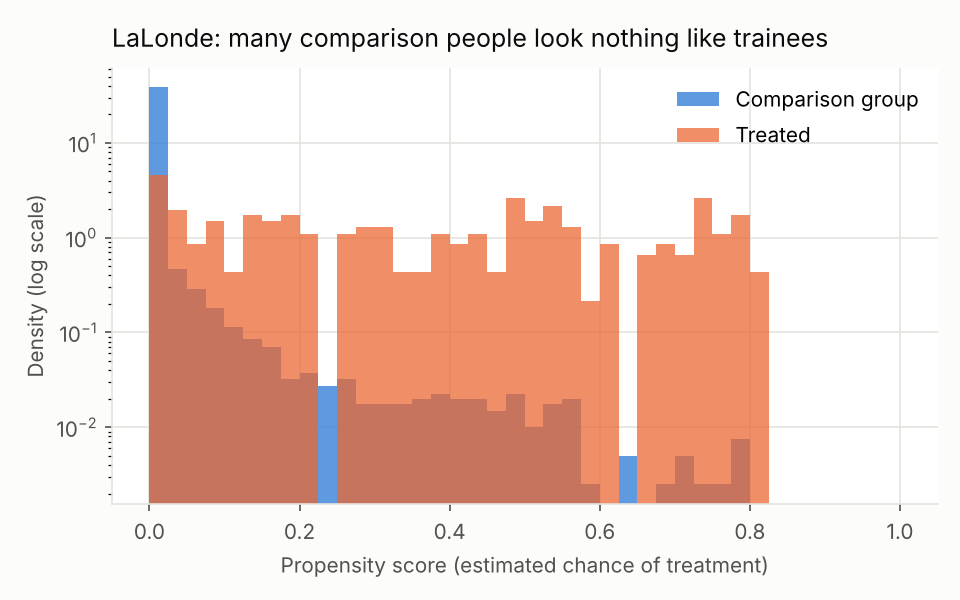

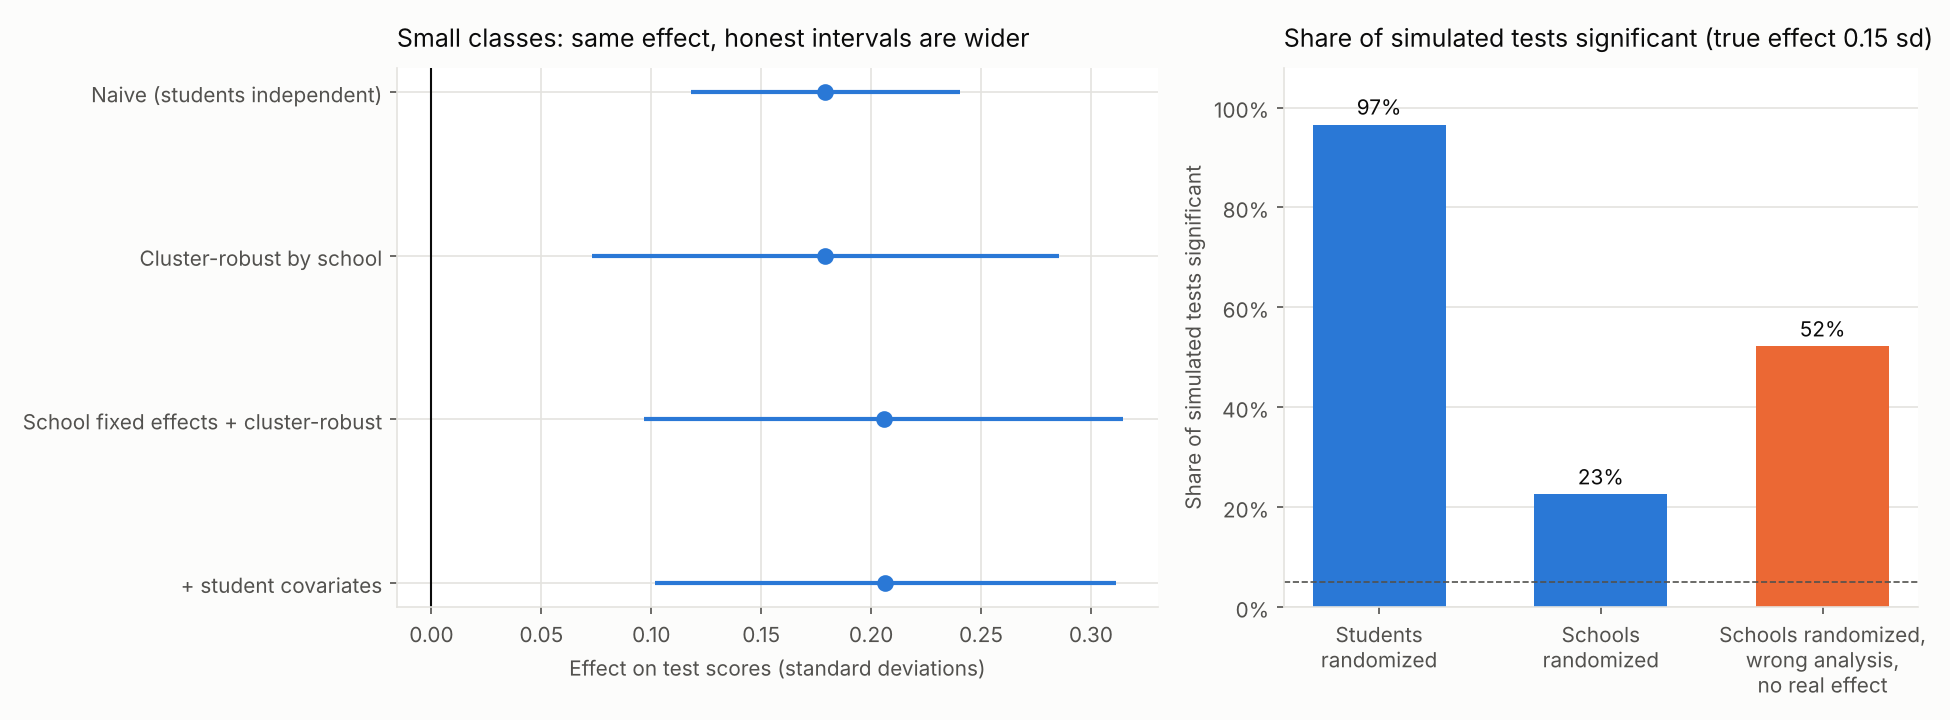

In [6]:
for f in ["experiment_lift", "bayes_probability", "cuped_variance_reduction", "proxy_validation",
          "observational_benchmark", "lalonde_overlap", "star_cluster"]:
    display(Image(f"reports/{f}.png", width=760))

## 5. Use the library on your own test
The functions in `src/measure` work on any experiment. For example:

In [7]:
import numpy as np
from src.measure import experiments as E, bayes
rng = np.random.default_rng(0)
control = rng.binomial(1, 0.100, 20_000)
treated = rng.binomial(1, 0.108, 20_000)
print(E.diff_in_means(treated, control))
print(bayes.beta_binomial(treated.sum(), len(treated), control.sum(), len(control)))
print("customers per group to detect +0.8 points:", E.required_n(0.008, control.std()))

{'effect': np.float64(0.0059999999999999915), 'se': np.float64(0.0030132132305395573), 'ci_low': np.float64(9.421059040287238e-05), 'ci_high': np.float64(0.01190578940959711), 'p_value': np.float64(0.046455628314060964), 'mean_treated': np.float64(0.104), 'mean_control': np.float64(0.098), 'n_treated': 20000, 'n_control': 20000, 'rel_lift': np.float64(0.06122448979591821), 'rel_ci_low': np.float64(0.0009190698425998178), 'rel_ci_high': np.float64(0.12516331407264292)}
{'effect_mean': 0.005993626793041101, 'cred_low': 8.817223246085164e-05, 'cred_high': 0.01193453226918798, 'prob_better': 0.976675, 'expected_loss': 2.622539480968147e-05, 'lift_mean': 0.06162291836085733, 'lift_low': 0.0008696117393016922, 'lift_high': 0.12553771669342673, 'rate_treated': 0.10403590778961583, 'rate_control': 0.09804228099657473}
customers per group to detect +0.8 points: 21682
